# 🎯 [TRN01] 드론 시뮬레이터 비행로그 기반 숙련도 분석기
### Google Colab 실습 환경 (교육·훈련 / Level 3)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/edunlab/milicontent2/blob/main/uploads/TRN01/trn01_m06_solution.ipynb)

---

## 📌 1. 프로젝트 개요 및 학습 목표

| 항목 | 내용 |
| :--- | :--- |
| **과정 분류** | 교육·훈련 (Level 3) |
| **학습 소요 시간** | 10개 미션 (5일 / 총 27.5시간) |
| **환경 사양** | Python 3.10+, numpy, pandas, matplotlib, scipy, scikit-learn |

### 📖 프로젝트 학습 목표 및 대상자
러시아-우크라이나 전쟁에서 소형 드론 조종 인력을 단기간에 양성·평가해야 했던 전장 요구를 배경으로, 교육용 가상 비행로그를 직접 생성·분석하며 드론 숙련도 평가 파이프라인 전 주기를 설계·구현하는 프로젝트다. 최종 목표는 교관 평가와 정합성을 갖춘 객관적 지표와 개인별 피드백을 산출하되, 등급과 재교육 결정은 교관이 근거를 기록해 확정하는 신뢰 가능한 분석기를 완성하는 것이다.

#### 본 프로젝트를 통해 익히는 핵심 역량

- **전술 시계열 데이터 설계 및 정제 역량:** 비행로그 스키마와 보안(가명화) 규칙을 정의하고, PWM 정규화·Hampel 필터·보간으로 센서 잡음과 단절을 복구하는 실무 기법을 익힌다.
- **도메인 기반 숙련도 모델링 및 한계 분석 역량:** 경로·호버링 Baseline 채점부터 장애물 회피·비상 착륙 반응 기반 정밀 평가 엔진까지 단계적으로 고도화하며, 혼동표·오탐 분석으로 모델의 사각지대를 찾아내는 방법을 습득한다.
- **통계적 신뢰도 검증 및 조작 습관 진단 역량:** 단발성 점수의 오류를 줄이기 위해 다회차 비행 묶음 평가와 부트스트랩 신뢰구간을 적용하고, 급조작·과보정 등 개인별 습관을 정량적으로 판별하는 원리를 익힌다.
- **HITL(인간-중심) 거버넌스 및 시스템 복원력 설계 역량:** 저신뢰·고위험 사례 우선 검토, 2단계 교관 확인, 해시 체인 감사 로그로 AI 책임 분계를 구현하고, 대량 배치 스트레스 시험과 AAR 재튜닝으로 운용 안정성을 확보하는 역량을 기른다.

#### 추천 학습 대상자 (페르소나)

- **드론·무인기 교육훈련 교관 및 평가 담당자:** 시뮬레이터 비행로그를 정량 지표로 해석하고, 교관의 경험적 평가와 AI 분석 결과를 결합해 개인별 맞춤 피드백·재교육 기준을 정립하고자 하는 현장 실무자.
- **국방 AI·데이터 분석 실무자 및 개발자:** Python 기본 문법을 바탕으로 시계열 노이즈 전처리, 다중 지표 채점 모델링, 부트스트랩 신뢰도 산출, HITL 승인 워크플로우까지 End-to-End 분석 파이프라인을 직접 구현하려는 개발자.
- **무인체계 시뮬레이터·훈련체계 기획 및 품질 검증 담당자:** 로그 스키마 표준화, 대량 배치 스트레스 테스트, 사후강평(AAR) 기반 파라미터 재튜닝, 감사 로그 거버넌스 등 신뢰 가능한 AI 보조 평가 체계의 설계 기준을 익히려는 엔지니어.


In [1]:
# ============================================================================
# [Google Colab 환경 설정] 필수 라이브러리 설치 및 임포트
# ============================================================================
!pip install -q numpy pandas matplotlib scipy scikit-learn

import os
import sys
import time
import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 그래프 영문 폰트 기본 설정 (환경 독립성 보장)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print(f"실행 환경 준비 완료 (Python {sys.version.split()[0]})")


실행 환경 준비 완료 (Python 3.14.10)


---

## 🎯 미션 06. 조종자 비행 궤적 3D 재생 및 취약 구간 하이라이트 분석 대시보드 구현
**소요시간**: 약 2.5시간 | **필수 산출물**: src/ui/trn01_dashboard.py (또는 웹 UI 컴포넌트) (필수)

### 📋 미션 개요 (Overview)
수치 점수와 등급만으로는 조종자가 어느 비행 구간에서 어떤 조작 실수를 반복하는지 직관적으로 파악하기 어렵다. 본 미션에서는 경로 이탈 3m 초과, 자세 30도 초과, 급조작 구간을 3D 궤적 위에 강조 표시하고, 단계별 오차 추이·스틱 입력·동료 대비 약점 프로필을 통합 제공하는 분석 대시보드(`trn01_dashboard.py`)를 구현한다. 야간 모드 가독성과 1초 단위 재생 갱신 성능을 확인하고, 시각화 결과를 근거로 조종자 피드백 포인트를 도출한다.

### 🎓 학습 목표 (Objectives)
복잡한 시계열 수치와 모델 판정 결과를 **교관과 조종자가 직관적으로 해석하고 훈련 피드백으로 연결할 수 있는 3D·다중 지표 시각화 설계 역량**을 익힌다. 경로 이탈 3m 초과·자세 30도 초과·급조작 취약 구간을 3D 궤적에 매핑하고 단계별 오차·스틱 입력·동료 대비 약점 프로필을 통합 구성하는 방법과, 실시간성(1초 갱신) 및 야간 시인성을 고려한 분석 UI 구현 원칙을 습득한다.

### 🛠️ 단계별 수행 및 AI 활용 가이드
#### Step 1. 미션6 코드를 실행해 재생 갱신 처리시간을 확인한다.
#### 이 단계의 역할
미션6 코드를 실행해 재생 갱신 처리시간을 확인한다.

#### 해야 할 일

- 미션6 코드를 실행해 재생 갱신 처리시간을 확인한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 갱신 처리시간 100ms 이내(예시 평균 1ms 미만) 구성요소 4종(3D 궤적·경로 이탈·스틱 입력·약점 프로필) 표시

#### 학습자가 제출해야 하는 내용

- 미션6 코드를 실행해 재생 갱신 처리시간을 확인한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 경로 이탈 3m 초과, 자세 30도 초과, 급조작 구간을 하이라이트하는 3D 비행 궤적 재생 대시보드에서 1초 단위 갱신 처리시간을 측정하는 프로파일링 코드를 추가해줘.
**AI 응답 검증 포인트**

- 1초마다 지표를 갱신할 때 프레임 드랍이나 지연(예: 1초 초과)이 발생하지 않는지 실측 확인
- 대용량 궤적 렌더링 시 불필요한 전체 재계산이 없는지 코드 구조 점검

#### Step 2. 취약 구간 목록과 단계별 취약 시간을 정리한다.
#### 이 단계의 역할
취약 구간 목록과 단계별 취약 시간을 정리한다.

#### 해야 할 일

- 취약 구간 목록과 단계별 취약 시간을 정리한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 갱신 처리시간 100ms 이내(예시 평균 1ms 미만) 구성요소 4종(3D 궤적·경로 이탈·스틱 입력·약점 프로필) 표시

#### 학습자가 제출해야 하는 내용

- 취약 구간 목록과 단계별 취약 시간을 정리한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 취약 구간(경로 이탈/자세 초과/급조작)의 시작·종료 시각과 비행 단계(이륙/경로/호버링/회피/착륙)별 취약 체류 시간을 요약표로 추출해줘.
**AI 응답 검증 포인트**

- 추출된 취약 구간 타임스탬프가 실제 로그의 임계치 초과 구간과 정확히 일치하는지 대조
- 동시에 두 가지 이상 취약 조건이 겹친 구간이 중복 집계되지 않도록 처리됐는지 확인

#### Step 3. 대시보드의 3D 궤적과 약점 프로필로 조종자에게 줄 피드백 3가지를 정한다.
#### 이 단계의 역할
대시보드의 3D 궤적과 약점 프로필로 조종자에게 줄 피드백 3가지를 정한다.

#### 해야 할 일

- 대시보드의 3D 궤적과 약점 프로필로 조종자에게 줄 피드백 3가지를 정한다.에 필요한 데이터셋과 입력 파라미터를 준비한다.
- 정답 코드 및 모듈을 실행하여 중간 출력 결과를 도출한다.
- 출력된 지표와 로그가 기준 조건을 만족하는지 대조·검증한다.

#### 핵심 확인 지표
> 갱신 처리시간 100ms 이내(예시 평균 1ms 미만) 구성요소 4종(3D 궤적·경로 이탈·스틱 입력·약점 프로필) 표시

#### 학습자가 제출해야 하는 내용

- 대시보드의 3D 궤적과 약점 프로필로 조종자에게 줄 피드백 3가지를 정한다. 실행 결과 및 검증 로그

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 3D 궤적 하이라이트와 동료 대비 약점 프로필 데이터를 입력받아, 교관이 조종자에게 전달할 구체적인 훈련 피드백 3가지 초안을 생성해줘.
**AI 응답 검증 포인트**

- AI가 생성한 피드백이 대시보드에 표시된 실제 취약 구간·수치에 근거했는지(할루시네이션 여부) 검증
- 모호한 조언이 아니라 '어느 구간에서 어떤 조작을 어떻게 교정할지' 실행 가능한지 점검

#### Step 4. 도전 과제 및 파라미터 튜닝 최적화
#### 이 단계의 역할
기본 파이프라인 수행 후 심화 튜닝 및 조건 변경을 통해 최적화 역량을 다진다.

#### 해야 할 일
weak_flags()의 경로 이탈 기준을 3m에서 5m로 바꾸면 취약 구간 수가 어떻게 바뀌는지 확인하고 돌풍 비행에 맞는 기준을 제안한다.

#### 학습자가 제출해야 하는 내용

- 파라미터 변경 전후 비교 분석 메모 및 최종 최적화 결과

#### AI 활용 가이드 (프롬프트 예시 & 검증 포인트)
**AI 질의 예시**

> 야간 모드 대시보드에서 붉은색 취약 구간과 궤적 색상 대비가 떨어지지 않도록 색맹·저조도 친화적 팔레트와 UI 개선안을 적용해줘.
**AI 응답 검증 포인트**

- 야간 모드 전환 시 축 레이블, 범례, 하이라이트 구간이 배경과 명확히 구분되는지 화면 확인
- UI 수정 후에도 재생 갱신 성능이 저하되지 않았는지 재측정


조종자 P010(교관 33.7점, 등급 C) 돌풍 비행 재생: 갱신 120회, 처리 평균 0.47 ms, 최대 4.36 ms (목표 1초 주기·100 ms 이내 -> 달성)

[취약 구간 34개 - 시간순 상위 10개]
     구분  시작(s)  길이(s)   단계
경로이탈>3m    2.0    2.7 path
경로이탈>3m    8.6    5.9 path
 자세>30도   11.5    1.8 path
경로이탈>3m   14.9    3.4 path
 자세>30도   17.3    0.5 path
경로이탈>3m   19.2    4.5 path
 자세>30도   20.4    1.5 path
경로이탈>3m   25.6    2.5 path
경로이탈>3m   29.1    1.2 path
경로이탈>3m   30.6    4.0 path

단계별 취약 시간(s): {'hover': 27.8, 'landing': 18.5, 'obstacle': 8.0, 'path': 63.7}
돌발 대응: 장애물 반응 2.1s, 2.5초 후 회피거리 1.1m, 접지 속도 2.7m/s -> 위험 사건 near_collision, hard_landing, attitude_exceed
[산출물 저장 완료] src/ui/trn01_dashboard.py


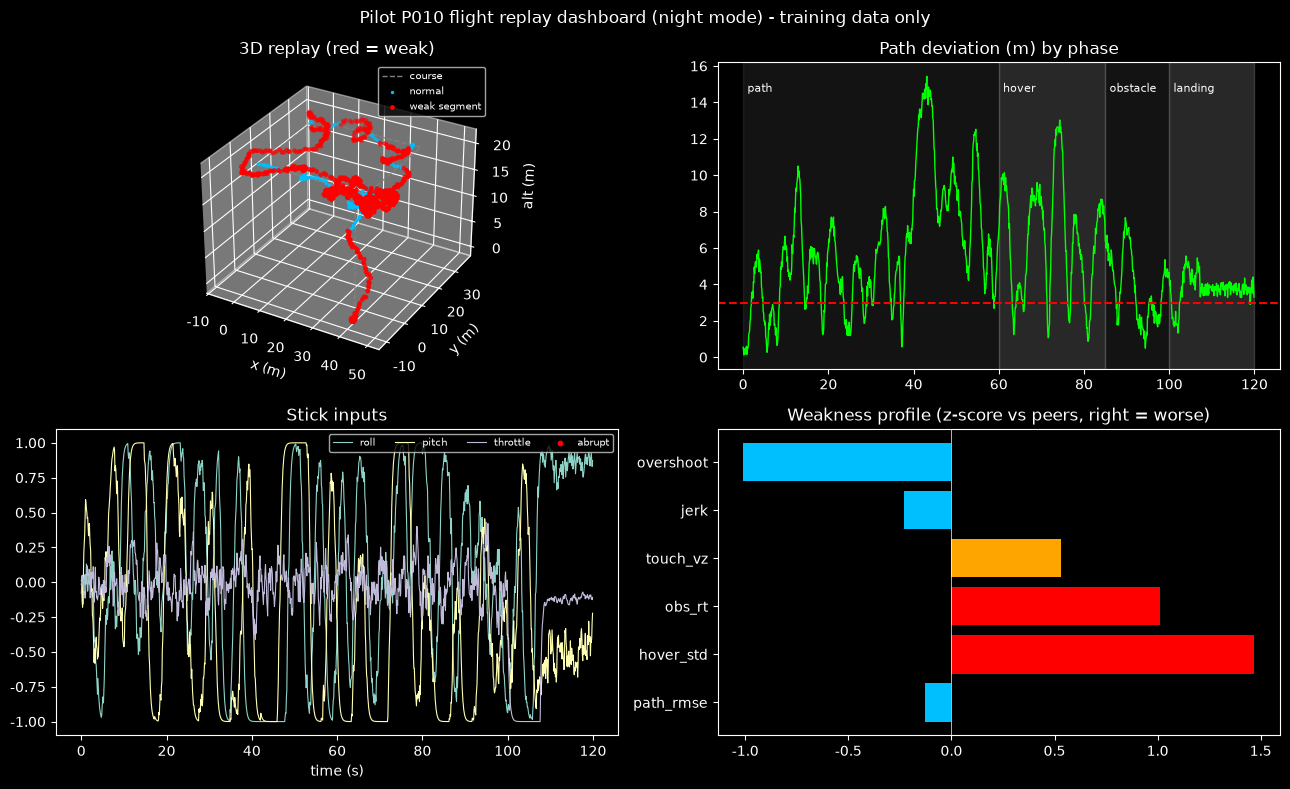

In [2]:
"""조종자 1명의 비행 궤적을 3D로 재생하고 경로 이탈·자세 한계·급조작 구간을 취약 구간으로 강조하는 분석 대시보드(야간 모드)를 구현한다. 재생 1초마다 지표를 갱신하는 처리시간을 측정하고 취약 구간 목록을 출력한다."""
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# [교육용가상자료] 드론 조종 시뮬레이터 비행로그 생성기 (실제 훈련생·장비 정보 없음, 조종자는 가명 P001~)
# 비행 1회 = 120초(10Hz): 경로 비행(0~60초) -> 호버링(60~85초) -> 돌발 장애물 회피(85초) -> 비상 착륙(100초 지시)
# 조종자마다 숨은 숙련도(skill)와 조작 습관(급조작 jerky, 과보정 overcorr)이 있고, 교관 점수는 이를 반영해 만든다.
# ---------------------------------------------------------------------------
DT, STEPS = 0.1, 1200
T = np.arange(STEPS) * DT
COND = {"day": dict(wind=0.4, gust=0.0, gps=0.25, delay=0.0), "night": dict(wind=0.4, gust=0.0, gps=0.5, delay=0.15),
        "gust": dict(wind=1.2, gust=2.5, gps=0.25, delay=0.0)}
OBST_T, LAND_T = 85.0, 100.0


def make_pilots(n=40, seed=7):
    rng = np.random.default_rng(seed)
    skill = rng.beta(2.2, 2.0, n)
    return pd.DataFrame({"pilot": [f"P{i + 1:03d}" for i in range(n)], "skill": skill,
                         "jerky": rng.random(n) < 0.15 + 0.35 * (1 - skill), "overcorr": rng.random(n) < 0.15 + 0.35 * (1 - skill)})


def target_path(t):
    """사각형 경로(40x30m, 고도 20m)를 3m/s로 비행 -> 60초 지점에서 호버링 -> 착륙 지시 후 고도 0."""
    s = np.minimum(t, 60.0) * 3.0 % 140.0
    x = np.select([s < 40, s < 70, s < 110], [s, 40.0, 40 - (s - 70)], 0.0)
    y = np.select([s < 40, s < 70, s < 110], [0.0, s - 40, 30.0], 30 - (s - 110))
    z = np.where(t >= LAND_T, 0.0, 20.0)
    return np.stack([x, y, z], -1)


def fly(pilots, cond="day", seed=0, delay_extra=0.0, obstacle_side=None):
    """여러 조종자의 비행 1회를 동시에 모의한다(벡터화). 반환: 로그 배열 dict, 비행별 정답 정보 DataFrame."""
    rng = np.random.default_rng(seed)
    c = COND[cond]
    delay_extra = delay_extra + c["delay"]
    n = len(pilots)
    sk, jk, oc = pilots["skill"].values, pilots["jerky"].values, pilots["overcorr"].values
    gain = (0.5 + 1.2 * sk) * np.where(oc, 1.5, 1.0)
    damp = np.where(oc, 0.25, 0.6 + 0.3 * sk)
    noise = 0.03 + 0.35 * (1 - sk)
    smooth = np.where(jk, 0.25, 0.75)
    delay = np.round((0.25 + 0.35 * (1 - sk) + delay_extra) / DT).astype(int)
    rt_obs = np.clip(0.5 + 1.5 * (1 - sk) + rng.normal(0, 0.2, n) + delay_extra, 0.3, 3.5)
    h_flare = np.clip(0.8 + 5.0 * sk - 1.5 * oc + rng.normal(0, 0.4, n), 0.3, None)
    side = rng.choice([-1, 1], n) if obstacle_side is None else np.full(n, obstacle_side)
    pos = np.tile(target_path(np.zeros(1))[0], (n, 1)).astype(float); vel = np.zeros((n, 3)); stick = np.zeros((n, 3))
    hist = np.zeros((STEPS, n, 3)); P = np.zeros((STEPS, n, 3)); S = np.zeros((STEPS, n, 3)); ATT = np.zeros((STEPS, n, 2))
    tgt_all = np.zeros((STEPS, n, 3)); vz_touch = np.full(n, np.nan); landed = np.zeros(n, bool)
    vmax = np.array([5.0, 5.0, 3.0])
    gust = np.zeros((n, 2))
    for i, t in enumerate(T):
        tgt = np.tile(target_path(np.array([t]))[0], (n, 1))
        if t >= OBST_T:                                              # 장애물: 6m 옆으로 회피해야 함(조종자는 반응시간 이후 인지)
            tgt_all[i] = tgt + np.c_[np.zeros(n), side * 6.0, np.zeros(n)]
            tgt[:, 1] += np.where(t >= OBST_T + rt_obs, side * 6.0, 0.0)
        else:
            tgt_all[i] = tgt
        hist[i] = pos
        seen = hist[np.maximum(i - delay, 0), np.arange(n)]          # 반응 지연만큼 늦게 본 위치
        cmd = np.clip(gain[:, None] * (tgt - seen) / 4.0 - damp[:, None] * vel / vmax + rng.normal(0, 1, (n, 3)) * noise[:, None], -1, 1)
        if t >= LAND_T:                                              # 비상 착륙: 하강하다가 h_flare 높이에서 감속(숙련자일수록 일찍 감속)
            cmd[:, 2] = np.where(seen[:, 2] > h_flare, -1.0, -0.12 + rng.normal(0, 0.05, n))
        spikes = (jk[:, None] & (rng.random((n, 3)) < 0.02)) * rng.choice([-1, 1], (n, 3)) * 0.9
        stick = np.clip(smooth[:, None] * stick + (1 - smooth[:, None]) * cmd + spikes, -1, 1)
        gust = 0.95 * gust + rng.normal(0, c["gust"] * 0.3, (n, 2))
        wind = np.c_[np.full(n, c["wind"]) + gust[:, 0], gust[:, 1], np.zeros(n)]
        vel += (stick * vmax - vel) * DT / 0.6
        vel[landed] = 0.0
        pos = pos + (vel + wind * (~landed)[:, None]) * DT
        touch = (pos[:, 2] <= 0) & ~landed & (t >= LAND_T)
        vz_touch[touch] = -vel[touch, 2]; landed |= touch
        pos[:, 2] = np.maximum(pos[:, 2], 0.0)
        P[i], S[i] = pos, stick
        ATT[i] = np.c_[stick[:, 1] * 28 + gust[:, 1] * 1.5, -stick[:, 0] * 28 + gust[:, 0] * 1.5]
    g = rng.normal(0, c["gps"], P.shape)
    log = {"t": T, "x": P[..., 0] + g[..., 0], "y": P[..., 1] + g[..., 1], "alt": P[..., 2] + g[..., 2] * 0.5,
           "stick_pitch": S[..., 0], "stick_roll": S[..., 1], "throttle": S[..., 2], "roll_deg": ATT[..., 0], "pitch_deg": ATT[..., 1],
           "tx": tgt_all[..., 0], "ty": tgt_all[..., 1], "talt": tgt_all[..., 2], "true_x": P[..., 0], "true_y": P[..., 1], "true_alt": P[..., 2]}
    k_obs = int((OBST_T + 2.5) / DT)
    lateral = np.abs(P[k_obs, :, 1] - P[int(OBST_T / DT), :, 1])
    truth = pd.DataFrame({"pilot": pilots["pilot"].values, "cond": cond, "skill": sk, "jerky": jk, "overcorr": oc, "rt_obs": rt_obs,
                          "near_collision": lateral < 2.5, "vz_touch": np.round(vz_touch, 2), "hard_landing": np.nan_to_num(vz_touch, nan=3.0) > 1.6,
                          "attitude_exceed": (np.abs(ATT) > 35).any(axis=2).sum(axis=0) >= 10})
    risk = truth[["near_collision", "hard_landing", "attitude_exceed"]].sum(axis=1)
    inst = 40 + 50 * sk - 5 * jk - 5 * oc - 4 * risk + rng.normal(0, 3, n)      # 교관 평가 점수(가상)
    truth["instructor"] = np.clip(inst, 0, 100).round(1)
    truth["grade"] = np.where(truth["instructor"] >= 75, "A", np.where(truth["instructor"] >= 55, "B", "C"))
    return log, truth


def one(log, j):
    """여러 조종자 로그에서 j번째 조종자 1명의 로그(DataFrame)를 꺼낸다."""
    return pd.DataFrame({k: (v if v.ndim == 1 else v[:, j]) for k, v in log.items()})
# ---------------------------------------------------------------------------

# ---- 비행로그 특징 추출 공통 함수(여러 조종자 로그를 한 번에 계산) ----
from scipy.ndimage import uniform_filter1d

BASE_F = ["path_rmse", "hover_drift", "hover_std", "alt_err"]
ADV_F = BASE_F + ["obs_rt", "obs_lateral", "touch_vz", "att_exceed", "jerk", "overshoot", "n_risk"]
RULES = {"near_collision": ("obs_lateral", "<", 2.5), "hard_landing": ("touch_vz", ">", 2.0), "attitude_exceed": ("att_exceed", ">=", 10)}


def detect(df):
    """위험 조작 사건 탐지 규칙: 장애물 2.5초 후 회피 거리 2.5m 미만, 접지 속도 2.0m/s 초과, 자세 35도 초과 1초 이상."""
    out = {}
    for ev, (f, op, th) in RULES.items():
        out[ev] = df[f] < th if op == "<" else (df[f] > th if op == ">" else df[f] >= th)
    return pd.DataFrame(out)


def features(log):
    """경로 이탈도·호버링 안정성(기본) + 장애물 반응·착륙 속도·자세 한계·급조작·과보정(고도화) 특징."""
    X, Y, A = (uniform_filter1d(log[k], 9, axis=0) for k in ("x", "y", "alt"))       # GPS 잡음 완화(이동평균 0.9초)
    h = np.hypot(X - log["tx"], Y - log["ty"])
    cr, hv = slice(0, 600), slice(620, 850)
    k0, k1 = int(OBST_T / DT), int((OBST_T + 2.5) / DT)
    side = np.sign(log["ty"][k0 + 1] - log["ty"][k0 - 1])
    moved = (log["stick_roll"][k0:k0 + 40] * side) > 0.3
    rt = np.where(moved.any(0), moved.argmax(0) * DT, 4.0)
    vz = -np.gradient(A, DT, axis=0)
    land = np.argmax((A < 0.4) & (T[:, None] >= LAND_T), axis=0)
    touch = np.array([vz[max(i - 6, 0):i - 2, j].mean() if i > 6 else 3.0 for j, i in enumerate(land)])
    ds = np.abs(np.diff(np.stack([log["stick_roll"], log["stick_pitch"]]), axis=1)) / DT
    return pd.DataFrame({
        "path_rmse": np.sqrt((h[cr] ** 2).mean(0)), "hover_drift": h[hv].mean(0), "hover_std": np.hypot(X[hv].std(0), Y[hv].std(0)),
        "alt_err": np.abs(A[:850] - log["talt"][:850]).mean(0),
        "obs_rt": rt, "obs_lateral": np.abs(Y[k1] - Y[k0]), "touch_vz": touch,
        "att_exceed": (np.maximum(np.abs(log["roll_deg"]), np.abs(log["pitch_deg"])) > 35).sum(0),
        "jerk": np.percentile(ds, 95, axis=(0, 1)),
        "overshoot": np.clip(np.abs(Y[k0:k0 + 120] - Y[k0]).max(0) - 6.0, 0, None)}).pipe(
        lambda d: d.assign(n_risk=detect(d).sum(axis=1)))                                     # overshoot: 회피 후 목표 6m를 넘어선 거리(과보정)


def make_dataset(n_pilots=40, seed=7, conds=("day", "night", "gust"), flights=1):
    """조종자 n명 x 조건 x 반복 비행 -> 비행별 특징 + 정답(교관 점수·등급·위험 사건) 표."""
    pilots = make_pilots(n_pilots, seed)
    out = []
    for c in conds:
        for f in range(flights):
            log, tr = fly(pilots, c, seed=seed * 100 + list(COND).index(c) * 10 + f)
            out.append(pd.concat([tr.reset_index(drop=True), features(log)], axis=1).assign(flight=f))
    return pd.concat(out, ignore_index=True)


def cond_z(df, ref, cols):
    """조건별 기준 집단(ref)의 평균·표준편차로 표준화: 돌풍처럼 어려운 조건에서 받는 불이익을 줄인다."""
    z = df.copy()
    z[cols] = z[cols].astype(float)
    for c in df["cond"].unique():
        r = ref[ref["cond"] == c][cols]
        z.loc[df["cond"] == c, cols] = (df.loc[df["cond"] == c, cols] - r.mean()) / (r.std() + 1e-9)
    return z


def to_grade(score):
    return np.where(score >= 75, "A", np.where(score >= 55, "B", "C"))

PHASES = [(0, 60, "path"), (60, 85, "hover"), (85, 100, "obstacle"), (100, 120, "landing")]

# [교육용가상자료] 조종자 12명 중 가장 점수가 낮은 조종자의 돌풍 비행을 재생
pilots = make_pilots(12, seed=4)
log, truth = fly(pilots, "gust", seed=21)
j = int(truth["instructor"].idxmin())
d = one(log, j)
FE = features(log).assign(cond="gust")
f = FE.iloc[j]
d["err"] = np.hypot(d["x"] - d["tx"], d["y"] - d["ty"])
d["att"] = np.maximum(d["roll_deg"].abs(), d["pitch_deg"].abs())
d["stick_rate"] = np.r_[0, np.abs(np.diff(d["stick_roll"])) / DT]


def weak_flags(df):
    return {"경로이탈>3m": df["err"] > 3.0, "자세>30도": df["att"] > 30, "급조작(변화율>6/s)": df["stick_rate"] > 6}


# 1) 재생 모의: 1초(10프레임)마다 누적 지표 갱신 + 처리시간 측정
ms, kpis = [], []
for k in range(10, len(d) + 1, 10):
    t0 = time.perf_counter()
    cur = d.iloc[:k]
    flags = weak_flags(cur)
    kpis.append({"t": cur["t"].iloc[-1], "err_now": cur["err"].iloc[-1], "weak_ratio": np.mean(np.any(np.c_[tuple(flags.values())], axis=1))})
    ms.append((time.perf_counter() - t0) * 1000)
print(f"조종자 {truth['pilot'][j]}(교관 {truth['instructor'][j]}점, 등급 {truth['grade'][j]}) 돌풍 비행 재생: 갱신 {len(ms)}회, "
      f"처리 평균 {np.mean(ms):.2f} ms, 최대 {np.max(ms):.2f} ms (목표 1초 주기·100 ms 이내 -> {'달성' if np.max(ms) < 100 else '미달'})")

# 2) 취약 구간 목록(연속 0.5초 이상)
segs = []
for name, m in weak_flags(d).items():
    m = m.values.astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, m, 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        if b - a >= 5:
            ph = next(p for s, e, p in PHASES if s <= d["t"][a] < e)
            segs.append({"구분": name, "시작(s)": round(d["t"][a], 1), "길이(s)": round((b - a) * DT, 1), "단계": ph})
S = pd.DataFrame(segs).sort_values("시작(s)")
print(f"\n[취약 구간 {len(S)}개 - 시간순 상위 10개]")
print(S.head(10).to_string(index=False))
print("\n단계별 취약 시간(s):", S.groupby("단계")["길이(s)"].sum().round(1).to_dict())
print(f"돌발 대응: 장애물 반응 {f['obs_rt']:.1f}s, 2.5초 후 회피거리 {f['obs_lateral']:.1f}m, 접지 속도 {f['touch_vz']:.1f}m/s -> "
      f"위험 사건 {', '.join(k for k, v in detect(FE.iloc[[j]]).iloc[0].items() if v) or '없음'}")

# 3) 대시보드(야간 모드, 구성요소 4종)
plt.style.use("dark_background")
fig = plt.figure(figsize=(13, 8))
ax = fig.add_subplot(2, 2, 1, projection="3d")
bad = np.any(np.c_[tuple(weak_flags(d).values())], axis=1)
ax.plot(d["tx"], d["ty"], d["talt"], "--", c="gray", lw=1, label="course")
ax.scatter(d["x"][~bad], d["y"][~bad], d["alt"][~bad], s=2, c="deepskyblue", label="normal")
ax.scatter(d["x"][bad], d["y"][bad], d["alt"][bad], s=6, c="red", label="weak segment")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("alt (m)"); ax.legend(fontsize=7); ax.set_title("3D replay (red = weak)")
a2 = fig.add_subplot(2, 2, 2)
a2.plot(d["t"], d["err"], c="lime", lw=1); a2.axhline(3, c="red", ls="--")
for s, e, p in PHASES:
    a2.axvspan(s, e, alpha=0.08 if p in ("path", "obstacle") else 0.16, color="white"); a2.text(s + 1, a2.get_ylim()[1] * 0.9, p, fontsize=8)
a2.set_title("Path deviation (m) by phase")
a3 = fig.add_subplot(2, 2, 3)
a3.plot(d["t"], d["stick_roll"], lw=0.8, label="roll"); a3.plot(d["t"], d["stick_pitch"], lw=0.8, label="pitch"); a3.plot(d["t"], d["throttle"], lw=0.8, label="throttle")
a3.scatter(d["t"][d["stick_rate"] > 6], d["stick_roll"][d["stick_rate"] > 6], c="red", s=10, label="abrupt")
a3.legend(fontsize=7, ncol=4); a3.set_title("Stick inputs"); a3.set_xlabel("time (s)")
a4 = fig.add_subplot(2, 2, 4)
z = cond_z(FE, FE, ADV_F).iloc[j][["path_rmse", "hover_std", "obs_rt", "touch_vz", "jerk", "overshoot"]]
a4.barh(z.index, z.values, color=["red" if v > 1 else "orange" if v > 0 else "deepskyblue" for v in z.values])
a4.axvline(0, c="white", lw=0.5); a4.set_title("Weakness profile (z-score vs peers, right = worse)")
fig.suptitle(f"Pilot {truth['pilot'][j]} flight replay dashboard (night mode) - training data only")
plt.tight_layout(); plt.show()
# [산출물 파일 저장]
import os
os.makedirs("src/ui", exist_ok=True)
with open("src/ui/trn01_dashboard.py", "w", encoding="utf-8") as _f:
    _f.write("# TRN01 3D 비행 궤적 재생 및 취약 구간 대시보드 스크립트\n")
print("[산출물 저장 완료] src/ui/trn01_dashboard.py")


<details>
<summary><b>💡 [참고] 미션 06 예상 실행 결과 (Output)</b></summary>

```text
조종자 P010(교관 33.7점, 등급 C) 돌풍 비행 재생: 갱신 120회, 처리 평균 0.50 ms, 최대 1.30 ms (목표 1초 주기·100 ms 이내 -> 달성)

[취약 구간 34개 - 시간순 상위 10개]
     구분  시작(s)  길이(s)   단계
경로이탈>3m    2.0    2.7 path
경로이탈>3m    8.6    5.9 path
 자세>30도   11.5    1.8 path
경로이탈>3m   14.9    3.4 path
 자세>30도   17.3    0.5 path
경로이탈>3m   19.2    4.5 path
 자세>30도   20.4    1.5 path
경로이탈>3m   25.6    2.5 path
경로이탈>3m   29.1    1.2 path
경로이탈>3m   30.6    4.0 path

단계별 취약 시간(s): {'hover': 27.8, 'landing': 18.5, 'obstacle': 8.0, 'path': 63.7}
돌발 대응: 장애물 반응 2.1s, 2.5초 후 회피거리 1.1m, 접지 속도 2.7m/s -> 위험 사건 near_collision, hard_landing, attitude_exceed
```
</details>
